# Project 19: Movie Search Engine using the Full MovieLens Dataset

## 1. Introduction & Full MovieLens Dataset Structure

### What is the MovieLens Dataset?
The MovieLens dataset is an industry-standard benchmark dataset compiled by GroupLens Research at the University of Minnesota. It provides comprehensive real-world user interaction data, including multi-star ratings, movie titles, genres, external database links, and millions of free-text descriptive tags.

### Dataset Files & Schema
In this project, our goal is to build an **Information Retrieval (IR) and Movie Search System**. To index and search movies effectively, we utilize four interconnected data files:

1. **`movies.csv`**: Contains core catalog metadata:
   - `movieId`: Unique identifier for each movie.
   - `title`: Movie title including release year (e.g., *Toy Story (1995)*).
   - `genres`: Pipe-separated list of genres (e.g., *Adventure|Animation|Children|Comedy|Fantasy*).
2. **`tags.csv`**: Contains free-text metadata applied by users:
   - `userId`: Anonymized user identifier.
   - `movieId`: Identifier linking to `movies.csv`.
   - `tag`: Free-text keywords describing plot points, themes, moods, actors, or styles (e.g., *atmospheric*, *sci-fi*, *twist ending*, *based on a book*).
   - `timestamp`: UTC epoch time when the tag was applied.
3. **`ratings.csv`**: Contains user rating activity:
   - `userId`, `movieId`, `rating` (0.5 to 5.0 stars), and `timestamp`.
   - In a search engine, ratings provide **relevance and popularity signals** (e.g., prioritizing highly-rated or widely-watched movies when query relevance is tied).
4. **`links.csv`**: Contains cross-reference identifiers (`imdbId`, `tmdbId`) linking MovieLens records to IMDb and The Movie Database (TMDb).

### Why Handling Missing Values Upfront Matters
In a search engine pipeline:
- Any missing (`NaN`) textual value can cause tokenizers or string manipulators to throw runtime errors or degrade index quality.
- By proactively inspecting and filling missing values (such as empty user tags or missing genres), we ensure our search index remains complete and reliable.


In [1]:
# ==============================================================================
# SECTION 1: LOAD THE COMPLETE DATASET & HANDLE MISSING VALUES
# ==============================================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Suppress minor warnings for clean output
warnings.filterwarnings('ignore')

# Set professional aesthetics for plots
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("Loading full MovieLens dataset files...")

# 1. Load movies metadata
movies_df = pd.read_csv('movies.csv')
# Handle missing titles or genres if any
movies_df['title'] = movies_df['title'].fillna('Unknown Title').astype(str).str.strip()
movies_df['genres'] = movies_df['genres'].fillna('(no genres listed)').astype(str).str.strip()

# 2. Load free-text user tags (plots, themes, keywords)
tags_df = pd.read_csv('tags.csv')
# Handle missing tags (fill missing values with empty string and strip whitespace)
tags_df['tag'] = tags_df['tag'].fillna('').astype(str).str.strip()

# 3. Load ratings dataset
# Specifying optimized 32-bit datatypes reduces RAM usage by over 50% for 25M-32M rows
ratings_df = pd.read_csv(
    'ratings.csv',
    dtype={'userId': 'int32', 'movieId': 'int32', 'rating': 'float32', 'timestamp': 'int32'}
)

# 4. Load external database identifiers (links)
links_df = pd.read_csv('links.csv')
# Handle missing TMDB IDs by filling with 0
links_df['tmdbId'] = links_df['tmdbId'].fillna(0).astype('int64')

# Summary of loaded dataset files
print("\n--- Dataset Loaded Successfully ---")
print(f"Movies Catalog:  {movies_df.shape[0]:,} movies  | {movies_df.shape[1]} columns")
print(f"User Tags:       {tags_df.shape[0]:,} tags    | {tags_df.shape[1]} columns")
print(f"User Ratings:    {ratings_df.shape[0]:,} ratings | {ratings_df.shape[1]} columns")
print(f"External Links:  {links_df.shape[0]:,} links   | {links_df.shape[1]} columns")


Loading full MovieLens dataset files...



--- Dataset Loaded Successfully ---
Movies Catalog:  87,585 movies  | 3 columns
User Tags:       2,000,072 tags    | 4 columns
User Ratings:    32,000,204 ratings | 4 columns
External Links:  87,585 links   | 3 columns


## 2. Data Cleaning and Statistical Checks

### Why Are We Cleaning the Data?
Before building a search engine, we must ensure our data is clean, unified, and statistically sound:
1. **Removing Empty Tags**: A small fraction of tag entries are blank strings. Removing these ensures our text vocabulary is not polluted with meaningless empty tokens.
2. **Aggregating Text per Movie**: Each movie in `tags.csv` has multiple individual tag rows submitted by different users. To turn each movie into a searchable "document", we group all user tags by `movieId` and combine them into a single descriptive text field (`all_tags`).
3. **Calculating Popularity & Quality Signals**: In search engines, ranking is not based purely on keyword matching; it also factors in popularity and rating quality. We calculate the total rating count and average rating for each movie from `ratings.csv`.
4. **Structural Checks**:
   - `df.info()`: Confirms memory footprint, non-null counts, and verifies that column datatypes are properly assigned.
   - `df.isnull().sum()`: Verifies that our cleaned search corpus has zero unexpected null values.
   - `df.describe(include='all')`: Provides a comprehensive one-line statistical summary showing counts, unique entries, top values, frequencies, and numerical metrics (mean, std, min, percentiles, max) across all columns.


In [2]:
# ==============================================================================
# SECTION 2: DATA CLEANING & STATISTICAL CHECKS
# ==============================================================================

# 1. Clean tags by removing empty rows and duplicate tag entries per user-movie
tags_clean = tags_df[tags_df['tag'] != ''].copy()
tags_clean.drop_duplicates(subset=['userId', 'movieId', 'tag'], inplace=True)

# 2. Aggregate tags per movie to build the text search document
# Grouping all tags for each movie into a single space-separated string
movie_tags_agg = (
    tags_clean.groupby('movieId')['tag']
    .apply(lambda tag_list: ' '.join(tag_list))
    .reset_index(name='all_tags')
)

# 3. Merge aggregated tags with movies catalog to create our primary search corpus
movies_clean_df = movies_df.merge(movie_tags_agg, on='movieId', how='left')
movies_clean_df['all_tags'] = movies_clean_df['all_tags'].fillna('')

# 4. Calculate movie rating statistics (rating count and average rating)
rating_stats = (
    ratings_df.groupby('movieId')['rating']
    .agg(rating_count='count', mean_rating='mean')
    .reset_index()
)
movies_clean_df = movies_clean_df.merge(rating_stats, on='movieId', how='left')
movies_clean_df['rating_count'] = movies_clean_df['rating_count'].fillna(0).astype('int32')
movies_clean_df['mean_rating'] = movies_clean_df['mean_rating'].fillna(0.0).round(2)

# Calculate document text length metrics for search analysis
movies_clean_df['tag_char_length'] = movies_clean_df['all_tags'].str.len()
movies_clean_df['tag_word_count'] = movies_clean_df['all_tags'].apply(lambda x: len(x.split()) if x else 0)

# ------------------------------------------------------------------------------
# Structural Check 1: df.info()
# ------------------------------------------------------------------------------
print("=" * 70)
print("1. STRUCTURAL CHECK: DataFrame Info")
print("=" * 70)
movies_clean_df.info()

# ------------------------------------------------------------------------------
# Structural Check 2: Missing Value Counts
# ------------------------------------------------------------------------------
print("\n" + "=" * 70)
print("2. STRUCTURAL CHECK: Missing Value Counts")
print("=" * 70)
print(movies_clean_df.isnull().sum())

# ------------------------------------------------------------------------------
# Structural Check 3: Comprehensive One-Line Summary with df.describe(include='all')
# ------------------------------------------------------------------------------
print("\n" + "=" * 70)
print("3. COMPREHENSIVE ONE-LINE SUMMARY: df.describe(include='all')")
print("=" * 70)
# One-line summary across all columns (numeric and text)
summary_table = movies_clean_df.describe(include='all')
print(summary_table)


1. STRUCTURAL CHECK: DataFrame Info
<class 'pandas.DataFrame'>
RangeIndex: 87585 entries, 0 to 87584
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   movieId          87585 non-null  int64  
 1   title            87585 non-null  str    
 2   genres           87585 non-null  str    
 3   all_tags         87585 non-null  str    
 4   rating_count     87585 non-null  int32  
 5   mean_rating      87585 non-null  float32
 6   tag_char_length  87585 non-null  int64  
 7   tag_word_count   87585 non-null  int64  
dtypes: float32(1), int32(1), int64(3), str(3)
memory usage: 31.0 MB

2. STRUCTURAL CHECK: Missing Value Counts
movieId            0
title              0
genres             0
all_tags           0
rating_count       0
mean_rating        0
tag_char_length    0
tag_word_count     0
dtype: int64

3. COMPREHENSIVE ONE-LINE SUMMARY: df.describe(include='all')
              movieId         title genres all_tags

## 3. Exploratory Data Analysis (EDA) for Search Engines

### Why Do Data Distributions Matter for Search Engines?
In an Information Retrieval (search engine) system, we build an **inverted index** and score documents using algorithms such as **BM25**, **TF-IDF**, or vector embeddings. Understanding data distributions is critical for search performance:

1. **Movie Genres Distribution (Plot 1)**:
   - Inverted index posting lists: Each genre acts as an indexed term pointing to matching movies.
   - Popular genres (e.g., *Drama*, *Comedy*) will have huge posting lists containing tens of thousands of movies, requiring efficient index compression and multi-tier filtering.
   - Rare genres (e.g., *Film-Noir*, *Western*) have short posting lists and require high-recall search strategies.

2. **Text Lengths Distribution for Plots & Tags (Plot 2)**:
   - BM25 document length normalization: Modern retrieval algorithms normalize term frequency by comparing document length ($dl$) to the average document length ($avgdl$).
   - If a movie has hundreds of tag words while another has only three, unnormalized search algorithms would artificially favor the longer document simply because query words appear more frequently by chance.
   - Understanding text length distributions guides how we tune BM25 hyperparameters ($b$ and $k_1$).

3. **Top User Tags Frequency (Plot 3)**:
   - User search vocabulary follows **Zipf's Law**: a handful of head terms occur very frequently, while a long tail of specific terms occur rarely.
   - The most frequent tags (e.g., *sci-fi*, *atmospheric*, *action*, *comedy*) represent high-intent search queries that should be leveraged for search autocompletion, facet filters, and query caching.


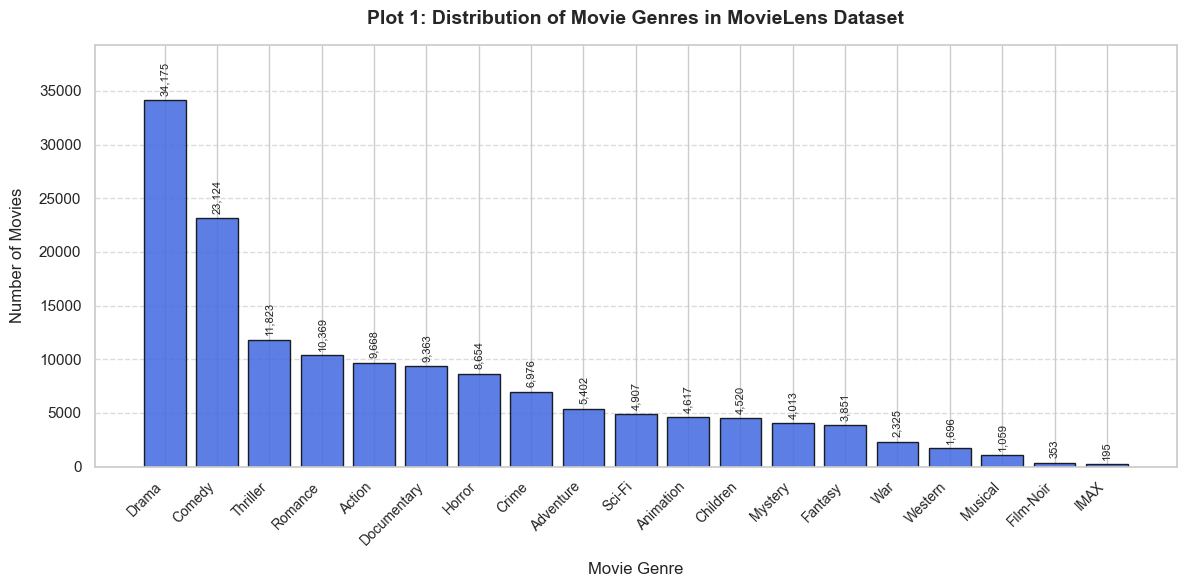

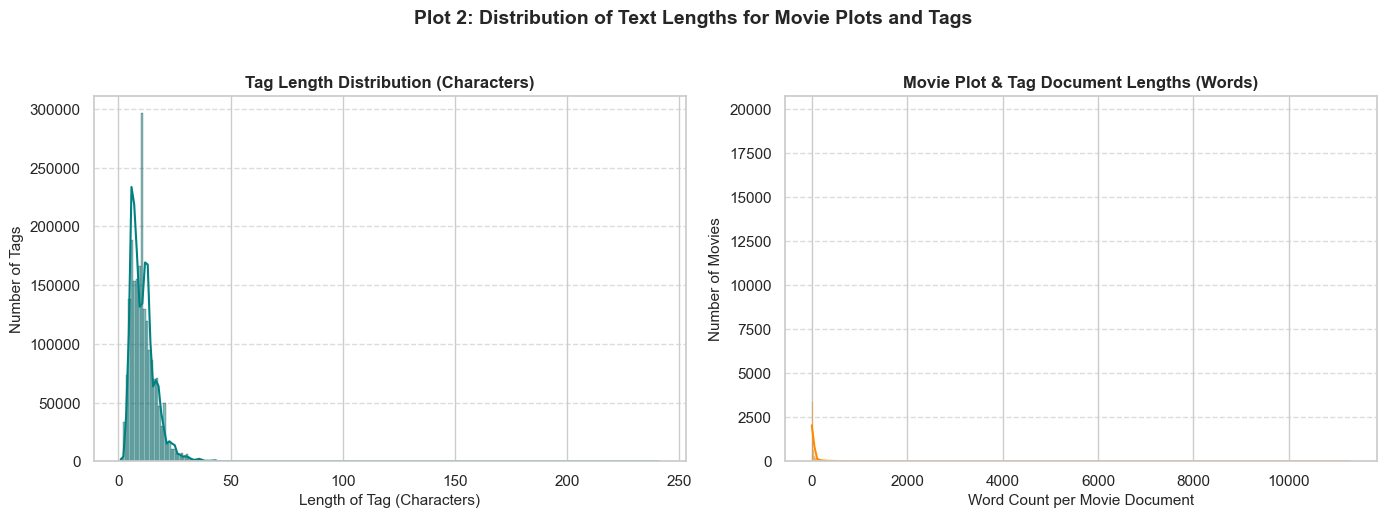

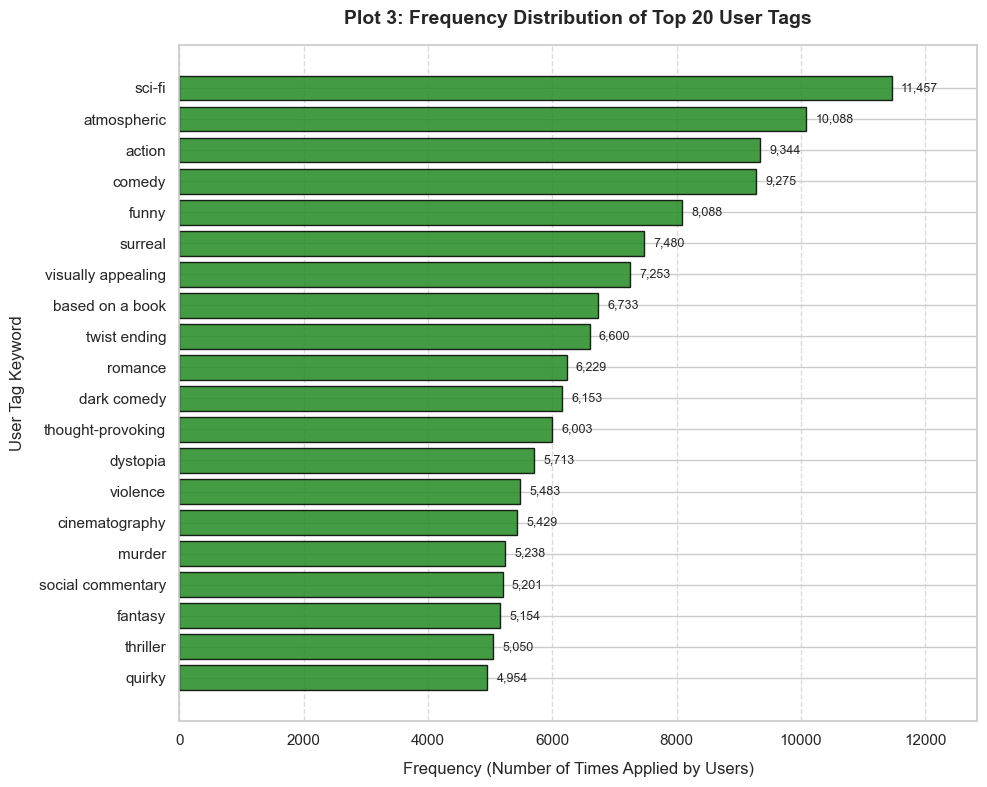

In [3]:
# ==============================================================================
# SECTION 3: EXPLORATORY DATA ANALYSIS (EDA) - 3 SIMPLE, CLEAR PLOTS
# ==============================================================================

# ------------------------------------------------------------------------------
# PLOT 1: Distribution of Movie Genres (Bar Chart)
# ------------------------------------------------------------------------------
# Split pipe-separated genres and count occurrences of each genre
all_genres = movies_clean_df['genres'].str.split('|').explode()
# Filter out placeholder '(no genres listed)'
genre_counts = all_genres[all_genres != '(no genres listed)'].value_counts()

plt.figure(figsize=(12, 6))
bars = plt.bar(genre_counts.index, genre_counts.values, color='royalblue', edgecolor='black', alpha=0.85)

plt.title('Plot 1: Distribution of Movie Genres in MovieLens Dataset', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Movie Genre', fontsize=12, labelpad=10)
plt.ylabel('Number of Movies', fontsize=12, labelpad=10)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add simple value labels on top of the bars for clarity
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 400, f'{int(height):,}', 
             ha='center', va='bottom', fontsize=8, rotation=90)

plt.ylim(0, genre_counts.max() * 1.15)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# PLOT 2: Distribution of Text Lengths for Movie Plots and Tags (Histogram)
# ------------------------------------------------------------------------------
# Calculate text lengths:
# (a) Individual user tag lengths in characters
individual_tag_lengths = tags_clean['tag'].str.len()
# (b) Aggregated movie plot/tag document lengths in words (for movies with tags)
movie_word_counts = movies_clean_df[movies_clean_df['tag_word_count'] > 0]['tag_word_count']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 2A: Individual tag length distribution
sns.histplot(individual_tag_lengths, bins=35, binrange=(1, 40), color='teal', edgecolor='black', kde=True, ax=axes[0])
axes[0].set_title('Tag Length Distribution (Characters)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Length of Tag (Characters)', fontsize=11)
axes[0].set_ylabel('Number of Tags', fontsize=11)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# Subplot 2B: Aggregated movie plot/tag document word count distribution
sns.histplot(movie_word_counts, bins=35, binrange=(1, 150), color='darkorange', edgecolor='black', kde=True, ax=axes[1])
axes[1].set_title('Movie Plot & Tag Document Lengths (Words)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Word Count per Movie Document', fontsize=11)
axes[1].set_ylabel('Number of Movies', fontsize=11)
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

plt.suptitle('Plot 2: Distribution of Text Lengths for Movie Plots and Tags', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# PLOT 3: Frequency Distribution of Top User Tags (Horizontal Bar Plot)
# ------------------------------------------------------------------------------
# Count frequency of each unique tag (standardized to lowercase)
top_20_tags = tags_clean['tag'].str.lower().value_counts().head(20)

plt.figure(figsize=(10, 8))
y_positions = range(len(top_20_tags))
plt.barh(y_positions, top_20_tags.values, color='forestgreen', edgecolor='black', alpha=0.85)

plt.title('Plot 3: Frequency Distribution of Top 20 User Tags', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Frequency (Number of Times Applied by Users)', fontsize=12, labelpad=10)
plt.ylabel('User Tag Keyword', fontsize=12, labelpad=10)
plt.yticks(y_positions, top_20_tags.index, fontsize=11)
plt.gca().invert_yaxis()  # Highest frequency tag at the top
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Add simple count labels next to bars
for i, count in enumerate(top_20_tags.values):
    plt.text(count + 150, i, f'{int(count):,}', va='center', fontsize=9)

plt.xlim(0, top_20_tags.max() * 1.12)
plt.tight_layout()
plt.show()
